# [F5:Facteurs de risque d'un portefeuille]


**Nom et prénom :** Fatima-ezzahra Naciri    **Code Apogée :** 23009384   **Groupe :** .Fin3..    **Filière :** S7 FIN / S7 CI    **Date :** 17/11/2026


**Dépôt GitHub :** https://github.com/votre-identifiant/CodeApogee-Nom-Groupe


## 1. Sujet et problématique
- **Intérêt du sujet**: Savoir d’où vient la rentabilité d’un portefeuille (exposition au marché, à la taille, à la valeur, ou performance « anormale »). Cela permet de distinguer ce qui rémunère un risque de ce qui relève d’un vrai alpha, et d’orienter la couverture et l’allocation. Le sujet combine régression, inférence statistique et validation sur des données financières bruitées.
- **Problématique** (une question) : La rentabilité mensuelle en excès d’un portefeuille de dix grandes entreprises américaines s’explique-t-elle par le marché, la taille et la valeur, ou subsiste-t-il un alpha significatif ?
- **Objectif mesurable** (métrique, référence, période de test, seuil) :
-Métrique : R² ajusté et RMSE hors échantillon du modèle à trois facteurs, avec la significativité de l’alpha (IC à 95 %).

Références : le CAPM (R² ajusté 0,606) et un modèle sans facteur (alpha seul).

-Période : 132 mois (janvier 2015 à décembre 2025), avec découpage chronologique 75 % / 25 % (99 mois d’estimation, 33 mois de test).

-Seuil : le modèle à trois facteurs doit battre le CAPM, avec un test F de modèles emboîtés significatif (p < 0,05) et un RMSE de test plus faible. Le rapport obtient un R² ajusté de 0,788 (contre 0,606), F = 56,9 (p < 0,0001) et un RMSE de 1,92 % contre 2,63 %. L’alpha est jugé non significatif si son IC à 95 % contient 0 (ici [−0,274 ; 0,389]).
- **Nature du problème** (et pourquoi) : Régression supervisée (variable cible continue : le rendement en excès), à visée explicative et non prédictive. On cherche à comprendre et à attribuer la rentabilité passée, pas à la prévoir : les facteurs utilisés sont ceux du même mois, donc inconnus à l’avance.
- **Algorithme principal envisagé** (n° de l'annexe A) : n° 1 de l’annexe A, la régression linéaire (Linear Regression). Régression linéaire multiple par moindres carrés ordinaires (MCO), avec écarts-types robustes de Newey-West.


## 2. Jeu de données
## 3. Exploration
## 4. Préparation
## 5. Algorithme
## 6. Protocole expérimental
## 7. Résultats
## 8. Analyse critique
## 9. Conclusion
## 10. Références et reproduction
## Déclaration des ressources et outils d'IA


## 2. Description du jeu de données

### 2.1 Sources, accès et date d'extraction

| | Facteurs Fama-French | Cours du portefeuille |
|---|---|---|
| **Nom** | *Fama/French 3 Factors* (`F-F_Research_Data_Factors`), mensuel | Cours de clôture ajustés mensuels de 10 titres |
| **Source** | Kenneth R. French, *Data Library*, Tuck School of Business, Dartmouth College | Yahoo Finance, via la bibliothèque Python `yfinance` |
| **URL d'accès** | https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Research_Data_Factors_CSV.zip | https://finance.yahoo.com (téléchargement par `yf.download`, tickers XOM, JPM, JNJ, PG, WMT, GE, T, KO, CVX, PFE) |
| **Date d'extraction** | [07/11/2026] ; fichier créé à partir de la base CRSP 202609 |
| **Licence / conditions** | Le fichier porte la mention « Copyright 2026 Eugene F. Fama and Kenneth R. French » ; aucune licence d'usage n'est indiquée dans le fichier. Usage ici : académique, avec citation de la source. | Aucune licence ouverte n'est indiquée ; données soumises aux conditions d'utilisation de Yahoo, que `yfinance` (outil non officiel) ne remplace pas. Usage ici : pédagogique, personnel. |

Pour dater l'extraction automatiquement, ajouter dans la cellule de chargement :
`import datetime; print("Extraction le", datetime.date.today())`

### 2.2 Taille, période, fréquence

- **Fichier Fama-French complet** : 1 203 observations mensuelles × 4 variables (+ la date), de juillet 1926 à septembre 2026, sans valeur manquante.
- **Cours Yahoo** : 133 cours mensuels par titre (décembre 2014 à décembre 2025), soit 132 rendements pour 10 titres.
- **Échantillon d'étude** (après fusion interne sur la date 202609) : **132 observations**, **17 colonnes** (date, 10 rendements de titres, rendement du portefeuille, 4 facteurs, rendement en excès), de **janvier 2015 à décembre 2025**.
- **Fréquence** : mensuelle.

> La période est limitée par la date de fin des cours Yahoo (`end="2025-12-31"`), et non par les facteurs, qui vont jusqu'à septembre 2026.

### 2.3 Unité d'observation

Une ligne = **un mois calendaire** (identifié par `Date` au format AAAAMM) : rendement du portefeuille de 10 titres et valeur des facteurs du même mois.

### 2.4 Dictionnaire des variables

| Variable | Type | Unité | Description |
|---|---|---|---|
| `Date` | texte (202609) | n/a | Mois d'observation, clé de fusion |
| `Portefeuille` | numérique | % | Rendement mensuel du portefeuille à pondération égale (1/10), rééquilibré chaque mois |
| `RF` | numérique | % | Taux sans risque mensuel (bon du Trésor à 1 mois) |
| `Mkt-RF` | numérique | % | Prime de risque du marché : rendement du marché américain moins `RF` |
| `SMB` | numérique | % | *Small Minus Big* : petites capitalisations moins grandes |
| `HML` | numérique | % | *High Minus Low* : titres « valeur » moins titres « croissance » |
| `Rp_exc` | numérique | % | **Cible** : `Portefeuille` − `RF` |

Sur l'échantillon (132 mois) : `Mkt-RF` a une moyenne de 0,99 % et un écart-type de 4,48 % ; `SMB` −0,18 % et 2,75 % ; `HML` −0,11 % et 3,72 % ; `RF` 0,16 % et 0,16 %.

### 2.5 Variable cible

`Rp_exc = Portefeuille − RF`, où `Portefeuille` est la moyenne simple des rendements mensuels (`pct_change() × 100`) des 10 titres, calculés sur les cours ajustés. Variable continue, donc un problème de régression. Les trois variables explicatives sont `Mkt-RF`, `SMB` et `HML`.

### 2.6 Adéquation avec la problématique

Les facteurs Fama-French sont la référence académique pour décomposer un rendement en exposition au marché, à la taille et à la valeur. Ils sont publics, mensuels et alignables sur des rendements de titres américains. Ils permettent de tester si la rentabilité du portefeuille s'explique par ces facteurs ou s'il reste un alpha.

### 2.7 Limites

- **Biais de survie** : les 10 titres existent encore en 2025, les sociétés disparues sont absentes, ce qui tend à surestimer l'alpha.
- **Opérations sur titres** : les cours ajustés ne corrigent pas toujours toutes les scissions (GE HealthCare et GE Vernova, WarnerMedia pour AT&T).
- **Représentativité** : 10 grandes capitalisations à tendance défensive ; les conclusions valent pour ce portefeuille, pas pour le marché américain.
- **Données manquantes** : aucune dans les facteurs ; à vérifier sur les cours (`rend.isna().sum()`).
- **Révisions** : les séries Fama-French sont recalculées à chaque mise à jour de la base CRSP, d'où l'importance de la date d'extraction.
- **Changements de régime** : la période inclut la crise de 2020 et la hausse des taux de 2022 ; les coefficients peuvent varier dans le temps.
- **Coûts de transaction** : ignorés (rééquilibrage mensuel supposé gratuit).

## Mon portefeuille

- **Composition** : 10 grandes entreprises américaines de secteurs différents :
  - énergie : Exxon Mobil (XOM), Chevron (CVX) ;
  - finance : JPMorgan Chase (JPM) ;
  - santé : Johnson & Johnson (JNJ), Pfizer (PFE) ;
  - consommation de base : Procter & Gamble (PG), Walmart (WMT), Coca-Cola (KO) ;
  - industrie : General Electric (GE) ;
  - télécommunications : AT&T (T).
- **Règle de sélection** : grandes entreprises établies, cotées aux États-Unis, déjà présentes en 2015, réparties sur six secteurs pour diversifier le risque.
- **Pondération** : égale (1/10 pour chaque titre), rééquilibrée chaque mois.
- **Source des cours** : Yahoo Finance (`yfinance`), cours de clôture ajustés (dividendes et divisions inclus), fréquence mensuelle.
- **Période** : janvier 2015 à décembre 2025 (132 mois), limitée par la date de fin des cours Yahoo (`end="2025-12-31"`) ; les facteurs Fama-French vont, eux, jusqu'à septembre 2026.
- **Limites** :
  - le portefeuille est composé d'entreprises qui existent encore aujourd'hui, ce qui crée un **biais de survie** (voir section 2.7 et section 8.2) ;
  - General Electric et AT&T ont connu des scissions d'activités (par exemple GE HealthCare et GE Vernova pour GE, WarnerMedia pour AT&T), que les cours ajustés de Yahoo ne corrigent pas forcément entièrement ;
  - portefeuille limité à 10 titres.

In [1]:
# Importation des bibliothèques
import io, zipfile, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import statsmodels.api as sm
from statsmodels.regression.rolling import RollingOLS
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.diagnostic import het_breuschpagan
import yfinance as yf

# Reproductibilité et style des graphiques
np.random.seed(42)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

In [5]:
df = pd.read_csv("/content/drive/MyDrive/F5/F-F_Research_Data_Factors.csv",skiprows=3)
print(df)


                                             Unnamed: 0   Mkt-RF      SMB  \
0                                                192607     2.89    -2.42   
1                                                192608     2.64    -1.44   
2                                                192609     0.38    -1.36   
3                                                192610    -3.27    -0.18   
4                                                192611     2.54    -0.17   
...                                                 ...      ...      ...   
1300                                               2022   -21.32    -6.99   
1301                                               2023    21.75    -3.53   
1302                                               2024    19.76   -11.31   
1303                                               2025    13.30   -10.79   
1304  Copyright 2026 Eugene F. Fama and Kenneth R. F...      NaN      NaN   

          HML       RF  
0       -2.75     0.22  
1        4.13     0.25  


In [6]:
tickers_list = ["XOM", "JPM", "JNJ", "PG", "WMT", "GE", "T", "KO", "CVX", "PFE"]
poids = pd.Series(1 / len(tickers_list), index=tickers_list)

prix = yf.download(tickers_list, start="2014-12-01", end="2025-12-31",
                   interval="1mo", auto_adjust=True, progress=False)["Close"][tickers_list]

# Rendements mensuels en %, puis rendement du portefeuille
rend = prix.pct_change().dropna(how="all") * 100
rend["Portefeuille"] = (rend[tickers_list] * poids).sum(axis=1)

# Alignement du format de date avec Fama-French (AAAAMM)
rend.index = pd.to_datetime(rend.index).strftime("%Y%m")
rend = rend.rename_axis("Date").reset_index()
print("Dimensions :", rend.shape)
rend.head()

Dimensions : (132, 12)


Ticker,Date,XOM,JPM,JNJ,PG,WMT,GE,T,KO,CVX,PFE,Portefeuille
0,201501,-5.440784,-12.544261,-4.236422,-6.806976,-1.047974,-5.461020,-0.145320,-2.486981,-8.602236,0.321030,-4.645094
1,201502,2.043507,12.688531,3.083246,0.996558,-1.235592,9.790363,4.981739,5.173695,5.069810,10.792811,5.338467
2,201503,-3.998154,-1.142299,-1.863224,-3.747192,-1.413041,-4.540221,-5.526573,-5.574021,-1.593522,1.369459,-2.802879
3,201504,2.788176,5.117989,-1.391658,-2.185084,-5.106390,9.149513,8.123983,0.024714,5.791544,-2.471967,1.984082
4,201505,-1.677142,3.983536,1.683724,-1.408632,-4.242503,0.701640,-0.288676,0.986204,-6.333199,3.264160,-0.333089


## 3. Exploration des données

### 3.1 Structure et statistiques descriptives

On examine la structure des données : types, valeurs manquantes et statistiques descriptives.

In [7]:
# Types des colonnes et nombre de valeurs non renseignées
rend.info()
print("\nValeurs manquantes par colonne :")
print(rend.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 132 entries, 0 to 131
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          132 non-null    object 
 1   XOM           132 non-null    float64
 2   JPM           132 non-null    float64
 3   JNJ           132 non-null    float64
 4   PG            132 non-null    float64
 5   WMT           132 non-null    float64
 6   GE            132 non-null    float64
 7   T             132 non-null    float64
 8   KO            132 non-null    float64
 9   CVX           132 non-null    float64
 10  PFE           132 non-null    float64
 11  Portefeuille  132 non-null    float64
dtypes: float64(11), object(1)
memory usage: 12.5+ KB

Valeurs manquantes par colonne :
Ticker
Date            0
XOM             0
JPM             0
JNJ             0
PG              0
WMT             0
GE              0
T               0
KO              0
CVX             0
PFE             0


Le tableau compte 132 lignes ; la date est un texte et les 11 autres colonnes (10 titres et portefeuille) sont numériques (`float64`). Le nombre de valeurs non renseignées est nul pour toutes les colonnes : aucune imputation n'est nécessaire.

In [8]:
# Statistiques descriptives des rendements mensuels (%)
rend.drop(columns="Date").describe().round(2)

Ticker,XOM,JPM,JNJ,PG,WMT,GE,T,KO,CVX,PFE,Portefeuille
count,132.00,132.00,132.00,132.00,132.00,132.00,132.00,132.00,132.00,132.00,132.00
mean,0.84,1.72,0.86,0.68,1.34,1.33,0.76,0.75,0.89,0.42,0.96
std,7.62,6.96,4.64,4.61,5.41,10.11,5.98,4.53,7.81,6.42,4.05
min,-26.19,-22.46,-12.15,-9.14,-15.62,-26.95,-17.23,-16.55,-22.37,-14.38,-13.34
25%,-2.76,-2.96,-1.89,-2.08,-1.80,-3.83,-2.80,-1.30,-3.11,-3.28,-1.04
50%,0.60,2.33,1.07,0.85,1.42,0.51,0.76,0.96,0.90,-0.72,1.04
75%,4.38,5.91,3.60,3.82,4.86,5.53,4.91,3.67,4.66,3.55,3.23
max,26.92,21.54,14.42,13.14,12.87,37.20,20.95,12.89,27.28,23.92,15.79


Le portefeuille a un rendement moyen de 0,96 % par mois et un écart-type de 4,05 %, nettement inférieur à celui de chaque titre pris isolément (de 4,5 % pour KO et PG à 10,1 % pour GE) : c'est l'effet de la diversification. Les mois extrêmes du portefeuille vont de −13,34 % à +15,79 %, très au-delà d'un mois ordinaire (écart interquartile d'environ 4,3 points : de −1,04 % à 3,23 %).

### 3.2 Qualité des données

| Problème | Méthode de détection | Décision | Justification |
|---|---|---|---|
| Valeurs manquantes | `isna().sum()` sur les rendements et les facteurs | Aucune imputation | Aucune valeur manquante n'est attendue ni observée (voir 3.1) |
| Doublons | `duplicated()` sur la date | Aucune suppression | Une seule ligne par mois |
| Valeurs atypiques | Règle de l'écart interquartile : hors de $[Q_1 - 1{,}5\,IQR \, ; \, Q_3 + 1{,}5\,IQR]$ (méthode robuste, sans standardisation) | **Conservées** | En finance, une valeur extrême est le plus souvent réelle (krach, rotation de marché, crise) ; la supprimer fausserait l'estimation du risque |

Le code construit aussi le tableau `expl` (rendements et facteurs alignés sur la date, période d'étude) qui sert **uniquement** aux graphiques de cette section ; les données d'analyse officielles sont construites en section 4.

In [11]:
import pandas as pd

# Préparation du DataFrame df (facteurs Fama-French)
# On renomme la première colonne en 'Date' et on s'assure qu'elle est au format texte (string)
ff_clean = df.rename(columns={df.columns[0]: "Date"}).copy()
ff_clean["Date"] = ff_clean["Date"].astype(str).str.strip()

# Conversion des facteurs en valeurs numériques au cas où
for col in ["Mkt-RF", "SMB", "HML", "RF"]:
    ff_clean[col] = pd.to_numeric(ff_clean[col], errors="coerce")

# Qualité des données : doublons, valeurs manquantes, valeurs atypiques
print("Doublons de date   - portefeuille :", int(rend["Date"].duplicated().sum()), "| facteurs :", int(ff_clean["Date"].duplicated().sum()))
print("Valeurs manquantes - portefeuille :", int(rend.isna().sum().sum()), "| facteurs :", int(ff_clean[["Mkt-RF", "SMB", "HML", "RF"]].isna().sum().sum()))

# Tableau d'exploration : rendements et facteurs de la période d'étude, alignés sur la date
etude = ff_clean[(ff_clean["Date"] >= "201501") & (ff_clean["Date"] <= "202512")].set_index("Date")
expl = rend.set_index("Date")[["Portefeuille"]].join(etude[["Mkt-RF", "SMB", "HML", "RF"]], how="inner")
expl["Rp_exc"] = expl["Portefeuille"] - expl["RF"]      # exploration seulement

# Valeurs atypiques (règle IQR)
cols = ["Portefeuille", "Mkt-RF", "SMB", "HML"]
q1, q3 = expl[cols].quantile(0.25), expl[cols].quantile(0.75)
iqr = q3 - q1
atyp = expl[cols].lt(q1 - 1.5 * iqr) | expl[cols].gt(q3 + 1.5 * iqr)

print("\nNombre de mois atypiques par variable :")
print(atyp.sum().to_string())
print("\nMois atypiques (rendements en %) :")
display(expl.loc[atyp.any(axis=1), cols].round(2))

Doublons de date   - portefeuille : 0 | facteurs : 0
Valeurs manquantes - portefeuille : 0 | facteurs : 12

Nombre de mois atypiques par variable :
Portefeuille    7
Mkt-RF          6
SMB             2
HML             5

Mois atypiques (rendements en %) :


,Portefeuille,Mkt-RF,SMB,HML
Date,,,,
201611,3.03,4.86,5.60,8.32
201802,-7.77,-3.64,0.27,-1.10
201812,-7.31,-9.55,-2.33,-1.88
202002,-10.20,-8.15,1.08,-3.82
202003,-13.34,-13.37,-4.69,-13.83
202004,9.99,13.60,2.50,-1.34
202011,15.17,12.45,5.81,2.09
202101,-0.74,-0.07,7.14,3.22
202201,2.58,-6.16,-5.93,12.86


Il n'y a ni doublon ni valeur manquante. La règle de l'écart interquartile signale quelques mois par facteur sur la période : 6 pour Mkt-RF, 2 pour SMB et 5 pour HML. Les plus marquants sont mars 2020 (Mkt-RF −13,37 %, HML −13,83 %) et avril 2020 (Mkt-RF +13,60 %), puis plusieurs mois de 2022 (HML +12,86 % en janvier, Mkt-RF −9,41 % en avril). Ce sont des épisodes de stress ou de rotation de marché réels : **tous ces mois sont conservés**. La sortie liste aussi les mois atypiques du portefeuille, dont le minimum (−13,34 %) et le maximum (+15,79 %) sont à plus de trois écarts-types de la moyenne.

### 3.3 Évolution du portefeuille

Le rendement cumulé du portefeuille est comparé à celui du marché (`Mkt-RF` + `RF`).

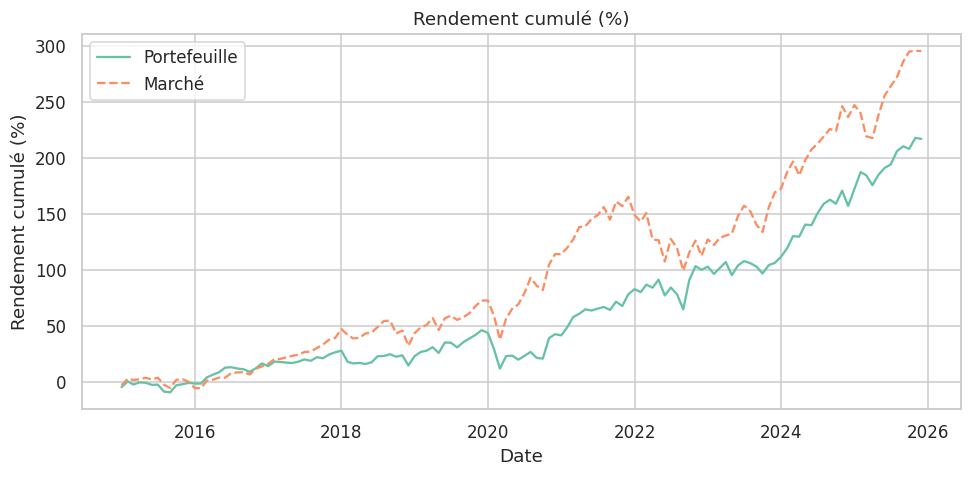

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# Conversion des index textuels (AAAAMM) en objets DateTime
dates_expl = pd.to_datetime(expl.index, format="%Y%m")

# Rendements cumulés : portefeuille et marché
cumul_p = (1 + expl["Portefeuille"] / 100).cumprod() - 1
cumul_m = (1 + (expl["Mkt-RF"] + expl["RF"]) / 100).cumprod() - 1

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(dates_expl, cumul_p * 100, label="Portefeuille")
ax.plot(dates_expl, cumul_m * 100, label="Marché", linestyle="--")
ax.set_title("Rendement cumulé (%)")
ax.set_xlabel("Date")
ax.set_ylabel("Rendement cumulé (%)")
ax.legend()
plt.tight_layout()
plt.show()

Sur la période, le portefeuille cumule environ +217 % contre environ +295 % pour le marché. Il évolue de façon plus régulière que le marché, avec un net décrochage en 2020, et fait moins bien que lui sur l'ensemble de la période, l'écart se creusant surtout à partir de 2024. Un portefeuille moins sensible que le marché doit sous-performer quand le marché monte fortement : on le vérifie par la régression.

### 3.4 Distribution des rendements en excès

L'histogramme montre la forme de la distribution (symétrie, queues épaisses), ce qui conditionne la validité des tests.

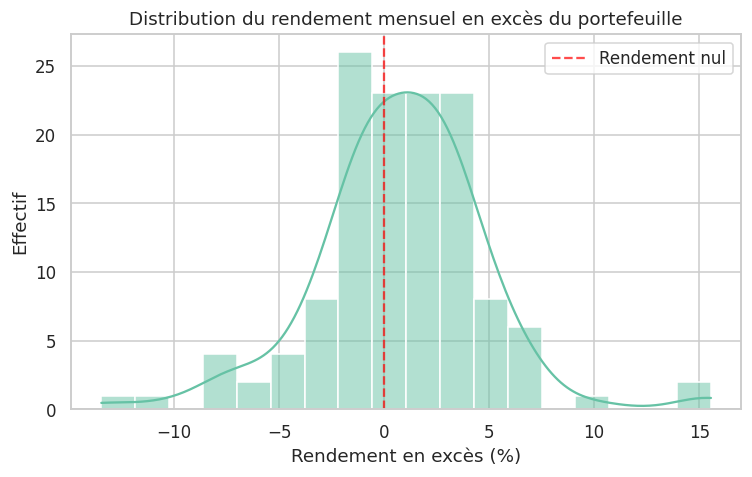

In [14]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.histplot(expl["Rp_exc"], kde=True, alpha=0.5, ax=ax)
ax.axvline(0, color="red", linestyle="--", alpha=0.7, label="Rendement nul")
ax.set_title("Distribution du rendement mensuel en excès du portefeuille")
ax.set_xlabel("Rendement en excès (%)")
ax.set_ylabel("Effectif")
ax.legend()
plt.tight_layout()
plt.show()

Le rendement mensuel en excès est en moyenne de 0,80 % (c'est l'alpha du modèle de référence), pour un écart-type d'environ 4 % : la dispersion vaut cinq fois la moyenne. La moyenne est donc estimée avec peu de précision (intervalle à 95 % de 0,10 % à 1,50 % par mois pour la référence, section 7.2), ce qui annonce que l'alpha sera difficile à distinguer de zéro.

### 3.5 Relation entre le portefeuille et le marché

Un nuage de points avec une droite de régression visualise le modèle à un facteur : **la pente est le bêta de marché**, l'ordonnée à l'origine est l'alpha.

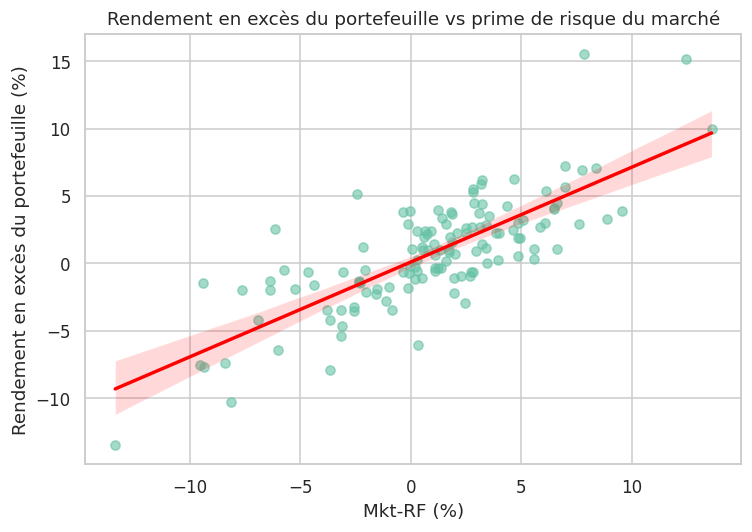

In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(data=expl, x="Mkt-RF", y="Rp_exc", scatter_kws={"alpha": 0.6}, line_kws={"color": "red"}, ax=ax)
ax.set_title("Rendement en excès du portefeuille vs prime de risque du marché")
ax.set_xlabel("Mkt-RF (%)")
ax.set_ylabel("Rendement en excès du portefeuille (%)")
plt.tight_layout()
plt.show()

Le nuage est nettement croissant et approximativement linéaire : le rendement du portefeuille suit la prime de risque du marché (corrélation de 0,78). La pente de la droite est le bêta du CAPM, soit 0,70 : un portefeuille moins sensible que le marché. La relation linéaire justifie le choix de la régression linéaire.

### 3.6 Boîtes à moustaches et corrélations

Les boîtes à moustaches comparent l'échelle des variables. La matrice de corrélation indique si les facteurs sont liés entre eux : **deux facteurs très corrélés (multicolinéarité) rendent les bêtas imprécis**.

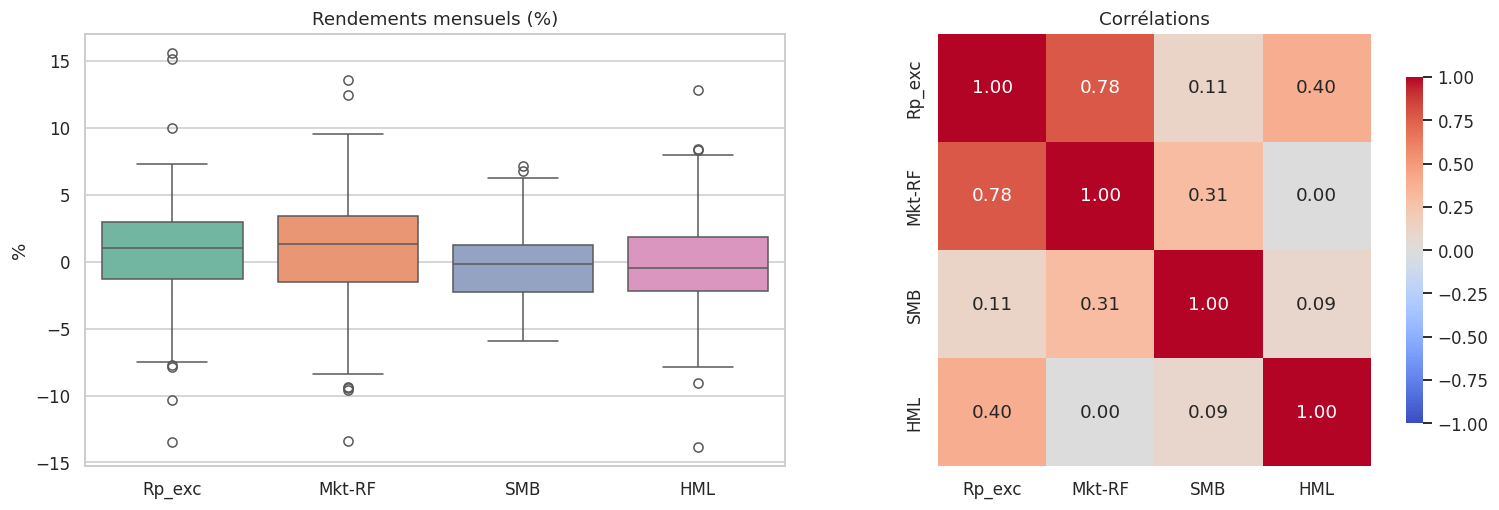

In [16]:
variables_reg = ["Rp_exc", "Mkt-RF", "SMB", "HML"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1]})
sns.boxplot(data=expl[variables_reg], ax=axes[0])
axes[0].set_title("Rendements mensuels (%)")
axes[0].set_ylabel("%")

sns.heatmap(expl[variables_reg].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.8}, ax=axes[1])
axes[1].set_title("Corrélations")
plt.tight_layout()
plt.show()

Le rendement en excès du portefeuille est fortement corrélé au marché (0,78), modérément à HML (0,40) et faiblement à SMB (0,11). Les trois facteurs sont peu corrélés entre eux (au plus 0,31 entre Mkt-RF et SMB) : il n'y a pas de multicolinéarité gênante, et leurs bêtas peuvent être estimés séparément. Les boîtes montrent que le marché est le facteur le plus dispersé et que SMB et HML ont des valeurs extrêmes des deux côtés.

## 4. Préparation des données

Chaque étape est justifiée ; les règles contre les fuites de données sont synthétisées en 6.3.

| Étape | Décision | Justification |
|---|---|---|
| Nettoyage | Fusion interne portefeuille / facteurs sur la date AAAAMM, puis suppression d'éventuelles lignes incomplètes | Garantit qu'un mois est associé aux facteurs du même mois ; aucune valeur manquante n'a été trouvée (3.2) |
| Création de variables | `Rp_exc = Portefeuille − RF` | La théorie (CAPM, Fama-French) porte sur les rendements **en excès** du taux sans risque |
| Encodage | Aucun | Toutes les variables sont numériques |
| Mise à l'échelle | **Aucune** | La régression par MCO est invariante à un changement d'échelle des variables explicatives (seuls les coefficients changent d'unité) ; ici les facteurs sont tous en % et les bêtas se lisent directement comme des sensibilités. Aucun algorithme sensible à l'échelle (distances, pénalisation) n'est utilisé |
| Découpage | Chronologique, 75 % / 25 %, sans mélange | Le test doit être postérieur à l'apprentissage (données datées) |

### 4.1 Fusion, nettoyage et variable cible

In [18]:
# 1) Alignement des dates et fusion
data = pd.merge(rend, ff_clean, on="Date", how="inner")

# 2) Rendement en excès du portefeuille
data["Rp_exc"] = data["Portefeuille"] - data["RF"]

# 3) Suppression d'éventuelles lignes incomplètes
data = data.dropna(subset=["Rp_exc", "Mkt-RF", "SMB", "HML"]).reset_index(drop=True)
dates = pd.to_datetime(data["Date"], format="%Y%m")

print("Observations après fusion et nettoyage :", len(data), "mois")
print("Période :", data["Date"].min(), "->", data["Date"].max())
data[["Date", "Portefeuille", "RF", "Rp_exc", "Mkt-RF", "SMB", "HML"]].head()

Observations après fusion et nettoyage : 132 mois
Période : 201501 -> 202512


,Date,Portefeuille,RF,Rp_exc,Mkt-RF,SMB,HML
0,201501,-4.645094,0.0,-4.645094,-3.10,-0.61,-3.48
1,201502,5.338467,0.0,5.338467,6.13,0.64,-1.75
2,201503,-2.802879,0.0,-2.802879,-1.11,3.06,-0.38
3,201504,1.984082,0.0,1.984082,0.59,-2.98,1.81
4,201505,-0.333089,0.0,-0.333089,1.37,0.96,-1.10


La fusion donne 132 mois, de janvier 2015 à décembre 2025, sans ligne supprimée. Les premières lignes montrent l'alignement des dates : janvier 2015 associe le rendement du portefeuille (−4,65 %) aux facteurs de **janvier 2015** (Mkt-RF −3,10 %). Le taux sans risque est nul sur ces premiers mois (taux directeurs proches de zéro), donc `Rp_exc` y est égal au rendement du portefeuille.

### 4.2 Découpage chronologique

Le jeu d'apprentissage regroupe les 75 % de mois les plus anciens, le jeu de test les 25 % les plus récents, **sans mélange aléatoire**. Les facteurs et la cible portent sur le même mois (objectif explicatif) : aucun retard ni horizon n'est construit, donc aucun écart (*gap*) entre apprentissage et test n'est nécessaire.

In [19]:
# Découpage chronologique 75 % / 25 % (sans mélange)
n_train = int(0.75 * len(data))
idx_train, idx_test = data.index[:n_train], data.index[n_train:]
print("Apprentissage :", len(idx_train), "mois,", data.loc[idx_train[0], "Date"], "->", data.loc[idx_train[-1], "Date"])
print("Test          :", len(idx_test), "mois,", data.loc[idx_test[0], "Date"], "->", data.loc[idx_test[-1], "Date"])

# Preuve d'alignement : deux dernières lignes d'apprentissage, deux premières lignes de test
cols_show = ["Date", "Rp_exc", "Mkt-RF", "SMB", "HML"]
pd.concat([data.loc[idx_train[-2:], cols_show], data.loc[idx_test[:2], cols_show]])

Apprentissage : 99 mois, 201501 -> 202303
Test          : 33 mois, 202304 -> 202512


,Date,Rp_exc,Mkt-RF,SMB,HML
97,202302,-3.543438,-2.57,1.05,-0.80
98,202303,2.231643,2.48,-5.48,-9.05
99,202304,2.384121,0.62,-3.37,-0.12
100,202305,-6.047136,0.34,1.60,-7.79


L'apprentissage couvre 99 mois (janvier 2015 à mars 2023) et le test 33 mois (avril 2023 à décembre 2025), tous postérieurs à l'apprentissage. Les quatre lignes affichées montrent que chaque cible est alignée sur les facteurs de sa propre date, sans décalage.

## 5. Algorithme : régression linéaire (n° 1 de l'annexe A)

**Présentation.** La **régression linéaire** (*Linear Regression*) appartient à la famille de l'apprentissage supervisé (régression). Elle explique une variable continue $y$ (ici le rendement mensuel en excès du portefeuille, `Rp_exc`) par une combinaison linéaire de variables explicatives $x_1, \dots, x_p$ (les facteurs) :
$$y_t = \alpha + \beta_1 x_{1,t} + \dots + \beta_p x_{p,t} + \varepsilon_t$$
où $t$ est le mois, $\alpha$ l'ordonnée à l'origine (l'alpha), $\beta_j$ les coefficients (paramètres appris) et $\varepsilon_t$ le résidu. Les paramètres sont choisis par **moindres carrés ordinaires** (MCO) : ils minimisent $\sum_t \varepsilon_t^2$. Cette méthode n'a pas d'hyperparamètre de réglage ; les seuls choix sont la liste des facteurs et, pour les écarts-types robustes de Newey-West, le nombre de retards (3).

*Entrée → apprentissage → sortie* : facteurs du mois → estimation des $\alpha$ et $\beta$ → rendement en excès expliqué, avec intervalles de confiance et tests de significativité.

- **Avantages** : coefficients directement interprétables (sensibilité à chaque facteur) ; inférence statistique complète (tests, intervalles de confiance), ce qui répond à l'objectif explicatif.
- **Limites** : sensible aux valeurs aberrantes et suppose une relation linéaire et des coefficients constants dans le temps.

**Pourquoi cet algorithme.** La relation avec le marché est approximativement linéaire (3.5), les facteurs sont peu corrélés (3.6), et le but est de comprendre l'origine de la rentabilité plutôt que de la prévoir.

Trois modèles sont comparés, du plus simple au plus riche. La **référence** (*baseline*) est un modèle sans facteur qui prédit toujours la moyenne du rendement en excès : l'alpha est alors simplement la moyenne.

| Modèle | Équation |
|---|---|
| **Référence** (sans facteur) | $R_p - R_f = \alpha + \varepsilon$ |
| **CAPM** (un facteur) | $R_p - R_f = \alpha + \beta\,(R_m - R_f) + \varepsilon$ |
| **Fama-French** (trois facteurs) | $R_p - R_f = \alpha + \beta_1 (R_m - R_f) + \beta_2 SMB + \beta_3 HML + \varepsilon$ |

Tout modèle utile doit faire mieux que la référence, et le modèle à trois facteurs doit apporter **plus que le CAPM**. Comme on ajoute des variables, on compare avec le **R² ajusté**, qui pénalise la complexité (le R² simple augmente toujours).

## 6. Protocole expérimental

### 6.1 Données et découpage

132 mois (janvier 2015 à décembre 2025). Découpage chronologique 75 % / 25 % (section 4.2) pour l'évaluation hors échantillon ; l'analyse explicative (coefficients, tests, diagnostics) utilise les 132 mois.

### 6.2 Métriques et tests

| Objectif | Métrique ou test |
|---|---|
| Qualité d'ajustement | R² ajusté, AIC |
| Apport de SMB et HML | Test F de modèles emboîtés ($H_0 : \beta_{SMB} = \beta_{HML} = 0$) |
| Alpha et bêtas | Estimations, intervalles de confiance à 95 %, p-values ; erreurs robustes de Newey-West (3 retards) ; bootstrap de l'alpha (2 000 tirages, `GRAINE = 42`) |
| Généralisation | RMSE et R² hors échantillon (défini par rapport à la référence) sur les 33 derniers mois |
| Validité du modèle | Résidus (Durbin-Watson, Jarque-Bera, Breusch-Pagan), coefficients sur fenêtre glissante de 36 mois |

**Réglage.** Aucun hyperparamètre n'est réglé : **0 configuration essayée**. Les trois spécifications (référence, CAPM, Fama-French) sont fixées à l'avance par la théorie.

### 6.3 Contrôle des fuites de données

| Règle | Application dans ce travail |
|---|---|
| 1. Découper avant de transformer | Sans objet : aucune transformation apprise (ni imputation, ni standardisation, ni encodage, ni sélection de variables) |
| 2. Pipeline | Sans objet pour la même raison ; pas de validation croisée |
| 3. Ordre du temps | Respecté : test (avril 2023 – décembre 2025) postérieur à l'apprentissage, sans mélange (4.2) |
| 4. Variables construites avec le passé | Les facteurs et la cible sont du **même** mois (objectif explicatif, pas de prévision) ; aucun retard ni moyenne glissante dans les variables du modèle ; alignement prouvé en 4.2 |
| 5. Écart pour un horizon | Sans objet : la cible couvre un seul mois |
| 6. Standardisation d'une série temporelle | Aucune standardisation |
| 7. Variables contenant la cible | `RF` est exclu des variables explicatives. Recouvrement mineur à signaler : le facteur de marché inclut les entreprises du portefeuille |
| 8. Test utilisé une fois | L'évaluation hors échantillon est faite une seule fois (7.5), avec 0 hyperparamètre réglé. Les analyses explicatives des autres sous-sections utilisent les 132 mois et ne mesurent pas la prévision |
| 9. Révisions des données | Signalé comme limite (2.11 et section 8) : facteurs recalculés par CRSP, cours ajustés recalculés par Yahoo |

## 7. Résultats

### 7.1 Estimation des trois modèles

In [20]:
y = data["Rp_exc"]
X0 = pd.DataFrame({"const": 1.0}, index=data.index)
X1 = sm.add_constant(data[["Mkt-RF"]])
X3 = sm.add_constant(data[["Mkt-RF", "SMB", "HML"]])

m_ref = sm.OLS(y, X0).fit()
m_capm = sm.OLS(y, X1).fit()
m_ff3 = sm.OLS(y, X3).fit()

print(m_ff3.summary())

                            OLS Regression Results                            
Dep. Variable:                 Rp_exc   R-squared:                       0.793
Model:                            OLS   Adj. R-squared:                  0.788
Method:                 Least Squares   F-statistic:                     163.5
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           1.34e-43
Time:                        10:31:33   Log-Likelihood:                -267.35
No. Observations:                 132   AIC:                             542.7
Df Residuals:                     128   BIC:                             554.2
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0573      0.168      0.342      0.7

Le modèle à trois facteurs explique 79 % de la variance (R² = 0,793 ; R² ajusté = 0,788 ; F = 163,5 ; p = 1,3·10⁻⁴³) avec un AIC de 542,7. Le résumé montre trois bêtas très significatifs et une constante (alpha) non significative : détail en 7.2.

### 7.2 Tableau comparatif

In [21]:
def ligne(modele, nom):
    ci = modele.conf_int().loc["const"]
    out = {
        "Modèle": nom,
        "Alpha (% / mois)": modele.params["const"],
        "IC 95 % alpha (bas)": ci[0],
        "IC 95 % alpha (haut)": ci[1],
        "p-value alpha": modele.pvalues["const"],
    }
    for f in ["Mkt-RF", "SMB", "HML"]:
        out[f"Bêta {f}"] = modele.params.get(f, np.nan)
        out[f"p-value {f}"] = modele.pvalues.get(f, np.nan)
    out["R²"] = modele.rsquared
    out["R² ajusté"] = modele.rsquared_adj
    out["AIC"] = modele.aic
    out["N"] = int(modele.nobs)
    return out

tableau = (pd.DataFrame([ligne(m_ref, "Référence (sans facteur)"),
                         ligne(m_capm, "CAPM (1 facteur)"),
                         ligne(m_ff3, "Fama-French (3 facteurs)")])
           .set_index("Modèle").T)
tableau.round(4)

Modèle,Référence (sans facteur),CAPM (1 facteur),Fama-French (3 facteurs)
Alpha (% / mois),0.8003,0.1037,0.0573
IC 95 % alpha (bas),0.1035,-0.3442,-0.2744
IC 95 % alpha (haut),1.4970,0.5517,0.3890
p-value alpha,0.0247,0.6476,0.7329
Bêta Mkt-RF,NaN,0.7044,0.7530
p-value Mkt-RF,NaN,0.0000,0.0000
Bêta SMB,NaN,NaN,-0.2654
p-value SMB,NaN,NaN,0.0000
Bêta HML,NaN,NaN,0.4456
p-value HML,NaN,NaN,0.0000


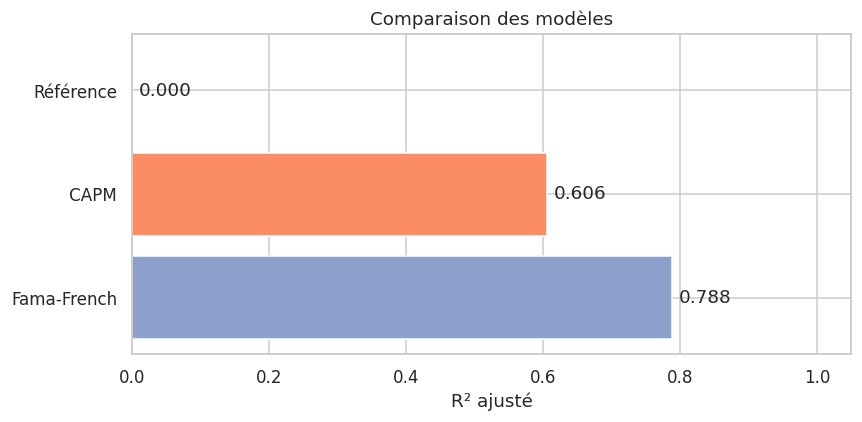

In [22]:
# Graphique : R² ajusté des trois modèles
fig, ax = plt.subplots(figsize=(8, 4))
valeurs = [m_ref.rsquared_adj, m_capm.rsquared_adj, m_ff3.rsquared_adj]
noms_m = ["Référence", "CAPM", "Fama-French"]
ax.barh(noms_m, valeurs, color=sns.color_palette("Set2", 3))
ax.invert_yaxis()
for i, v in enumerate(valeurs):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center")
ax.set_xlim(0, 1.05)
ax.set_xlabel("R² ajusté")
ax.set_title("Comparaison des modèles")
plt.tight_layout()
plt.show()

L'alpha « brut » de la référence (0,80 % par mois, p = 0,025) disparaît dès que l'on tient compte du marché (0,10 %, p = 0,648 avec le CAPM) et reste proche de zéro avec trois facteurs (0,057 %, p = 0,733 ; intervalle à 95 % de −0,274 à 0,389). Le R² ajusté passe de 0,606 (CAPM) à 0,788 (trois facteurs) et l'AIC diminue de 622,7 à 542,7. La rentabilité moyenne rémunère donc l'exposition au risque de marché, et non une performance supérieure.

### 7.3 Le modèle à trois facteurs apporte-t-il vraiment plus ?

Le **test F de modèles emboîtés** teste $H_0 : \beta_{SMB} = \beta_{HML} = 0$. Si la p-value est inférieure à 0,05, ajouter la taille et la valeur améliore significativement le modèle.

In [23]:
f_stat, p_f, ddl = m_ff3.compare_f_test(m_capm)
print(f"Test F (SMB et HML ajoutés au CAPM) : F = {f_stat:.2f}, p-value = {p_f:.4f}")
print(f"R² ajusté : CAPM = {m_capm.rsquared_adj:.3f} | Fama-French = {m_ff3.rsquared_adj:.3f}")
print(f"AIC       : CAPM = {m_capm.aic:.1f} | Fama-French = {m_ff3.aic:.1f}  (plus bas = meilleur)")

Test F (SMB et HML ajoutés au CAPM) : F = 56.91, p-value = 0.0000
R² ajusté : CAPM = 0.606 | Fama-French = 0.788
AIC       : CAPM = 622.7 | Fama-French = 542.7  (plus bas = meilleur)


Le test F de modèles emboîtés donne F = 56,91 avec une p-value inférieure à 0,0001 : la taille et la valeur apportent une information significative en plus du marché. Environ 61 % de la variance est expliquée par le marché seul et 18 points supplémentaires par SMB et HML.

### 7.4 Robustesse des tests

Les p-values du tableau supposent des erreurs de variance constante et sans autocorrélation. On les compare à des erreurs **robustes** (Newey-West, `HAC`). Si les conclusions ne changent pas, elles sont plus fiables.

In [24]:
m_ff3_hac = sm.OLS(y, X3).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
comparaison = pd.DataFrame({
    "Coefficient": m_ff3.params,
    "p-value (MCO)": m_ff3.pvalues,
    "p-value (robuste HAC)": m_ff3_hac.pvalues,
})
comparaison.round(4)

,Coefficient,p-value (MCO),p-value (robuste HAC)
const,0.0573,0.7329,0.7268
Mkt-RF,0.7530,0.0000,0.0000
SMB,-0.2654,0.0000,0.0001
HML,0.4456,0.0000,0.0000


Avec les écarts-types robustes de Newey-West, les p-values sont presque identiques à celles des MCO (alpha 0,727 contre 0,733 ; SMB 0,0001 contre moins de 0,0001). Les conclusions ne changent pas : les trois bêtas restent significatifs et l'alpha non significatif.

### 7.5 Évaluation hors échantillon

Un bon ajustement sur l'échantillon peut cacher du surapprentissage. Comme dans le TP des manchots, on garde un **jeu de test** à l'écart : ici, les derniers mois (découpage **chronologique**, jamais aléatoire pour des séries temporelles). On compare l'erreur de chaque modèle à celle de la référence.

In [25]:
resultats = []
for nom, X_full in [("Référence", X0), ("CAPM", X1), ("Fama-French", X3)]:
    modele = sm.OLS(y.loc[idx_train], X_full.loc[idx_train]).fit()
    pred = modele.predict(X_full.loc[idx_test])
    erreur = y.loc[idx_test] - pred
    resultats.append({"Modèle": nom, "RMSE test (%)": float(np.sqrt((erreur ** 2).mean())),
                      "SSE": float((erreur ** 2).sum())})

tab_test = pd.DataFrame(resultats).set_index("Modèle")
sse_ref = tab_test.loc["Référence", "SSE"]
tab_test["R² hors échantillon"] = 1 - tab_test["SSE"] / sse_ref
tab_test.drop(columns="SSE").round(3)

,RMSE test (%),R² hors échantillon
Modèle,,
Référence,2.988,0.000
CAPM,2.631,0.225
Fama-French,1.920,0.587


Sur les 33 mois de test, le modèle à trois facteurs réduit l'erreur de près de 36 % par rapport à la référence (RMSE de 1,92 % contre 2,99 %) et bat nettement le CAPM (2,63 %). Le R² hors échantillon est de 0,587, contre 0,225 pour le CAPM. Le classement est le même que dans l'échantillon, mais le test ne porte que sur 33 mois et utilise les facteurs du même mois : il mesure le pouvoir explicatif, pas une capacité de prévision.

### 7.6 Diagnostic du modèle à trois facteurs : analyse des résidus

Les tests de significativité supposent que les résidus ne présentent ni structure, ni autocorrélation, ni forte non-normalité. On le vérifie graphiquement et par des tests.

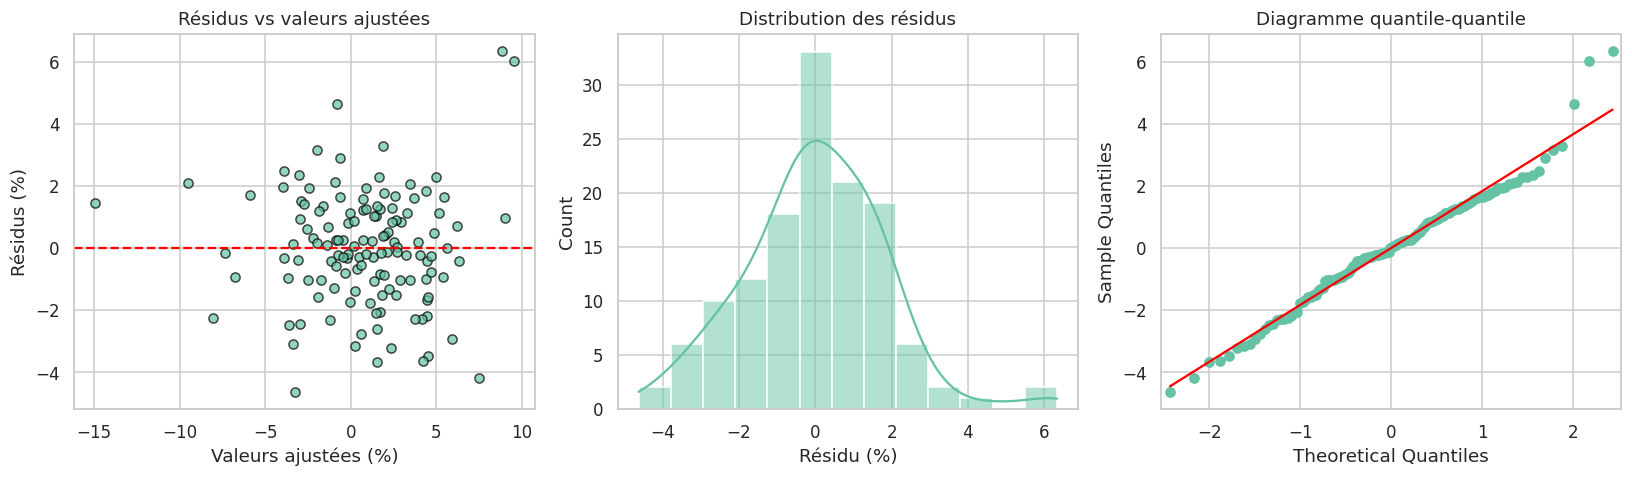

Durbin-Watson (autocorrélation, proche de 2 = absente) : 1.74
Jarque-Bera (normalité)            : p = 0.019
Breusch-Pagan (variance constante) : p = 0.089


In [27]:
residus = m_ff3.resid
ajustees = m_ff3.fittedvalues

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].scatter(ajustees, residus, alpha=0.7, edgecolor="k")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Résidus vs valeurs ajustées")
axes[0].set_xlabel("Valeurs ajustées (%)")
axes[0].set_ylabel("Résidus (%)")

sns.histplot(residus, kde=True, alpha=0.5, ax=axes[1])
axes[1].set_title("Distribution des résidus")
axes[1].set_xlabel("Résidu (%)")

sm.qqplot(residus, line="s", ax=axes[2])
axes[2].set_title("Diagramme quantile-quantile")
plt.tight_layout()
plt.show()

jb_stat, jb_p, skew, kurt = jarque_bera(residus)
bp_stat, bp_p, _, _ = het_breuschpagan(residus, X3)
print(f"Durbin-Watson (autocorrélation, proche de 2 = absente) : {durbin_watson(residus):.2f}")
print(f"Jarque-Bera (normalité)            : p = {jb_p:.3f}")
print(f"Breusch-Pagan (variance constante) : p = {bp_p:.3f}")

Les résidus ne présentent pas de structure visible en fonction des valeurs ajustées et la variance paraît constante (Breusch-Pagan : p = 0,089, non significatif). La normalité est rejetée à 5 % (Jarque-Bera : p = 0,019 ; asymétrie 0,26 et kurtosis 4,08, soit des queues un peu épaisses), et le Durbin-Watson de 1,74 suggère une légère autocorrélation positive. Ces écarts justifient les erreurs robustes de Newey-West de 7.4, qui ne changent pas les conclusions ; avec 132 observations, les tests restent raisonnablement fiables malgré la non-normalité.

### 7.7 Stabilité des coefficients dans le temps

C'est l'équivalent de la courbe d'apprentissage : on estime le modèle sur une **fenêtre glissante de 36 mois**. Si l'alpha et les bêtas bougent beaucoup, l'hypothèse de coefficients constants est fragile.

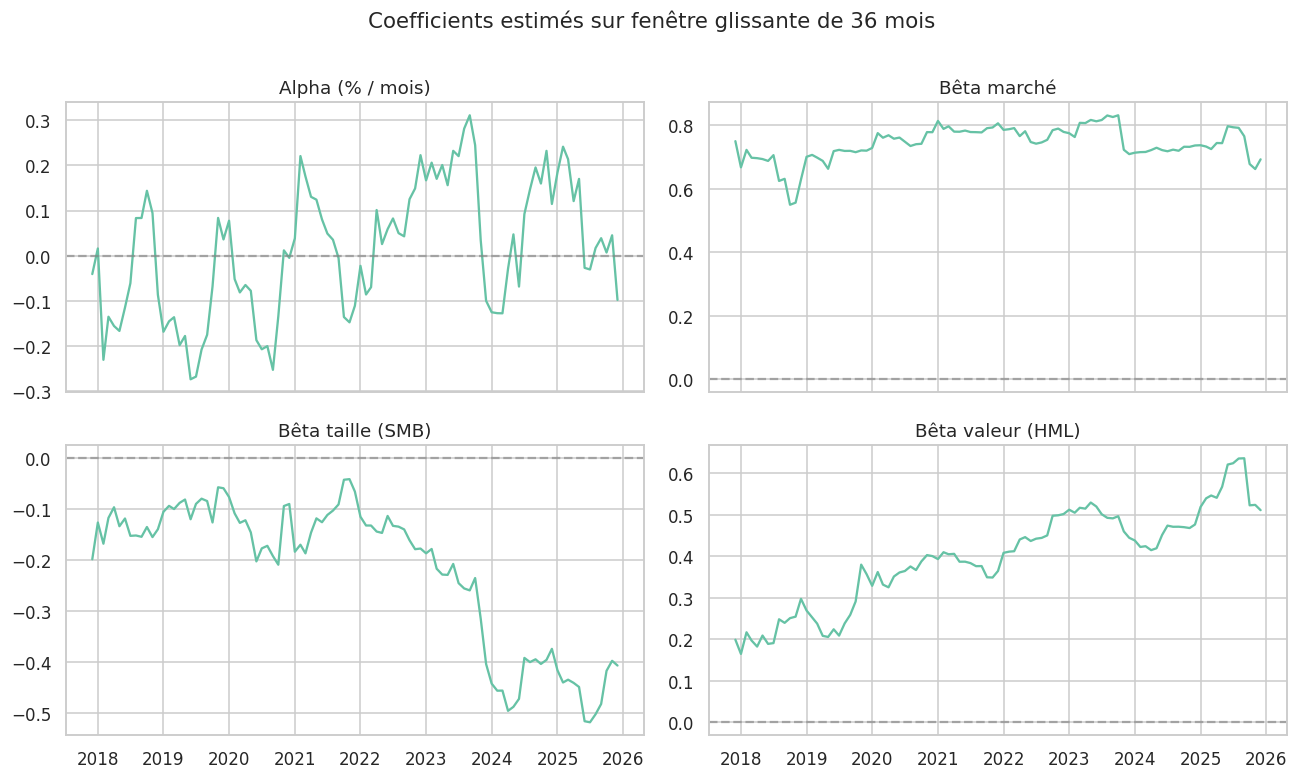

In [28]:
fenetre = 36
roll = RollingOLS(y, X3, window=fenetre).fit()
params_roll = roll.params.copy()
params_roll.index = dates

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, col, titre in zip(axes.ravel(), ["const", "Mkt-RF", "SMB", "HML"],
                          ["Alpha (% / mois)", "Bêta marché", "Bêta taille (SMB)", "Bêta valeur (HML)"]):
    ax.plot(params_roll.index, params_roll[col])
    ax.axhline(0, color="grey", linestyle="--", alpha=0.6)
    ax.set_title(titre)
plt.suptitle(f"Coefficients estimés sur fenêtre glissante de {fenetre} mois", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

Le bêta de marché est relativement stable (entre 0,55 et 0,83). Le bêta SMB passe d'environ −0,1 à environ −0,4 ou −0,5 à partir de 2023 et le bêta HML augmente de 0,2 à plus de 0,5. L'alpha oscille de part et d'autre de zéro (d'environ −0,27 à +0,31 % par mois) sans tendance claire. L'hypothèse de coefficients constants n'est donc qu'une approximation : les valeurs estimées sur toute la période sont des moyennes de régimes différents.

### 7.8 Coefficients et intervalles de confiance

Le graphique montre chaque coefficient avec son intervalle de confiance à 95 %. **Un intervalle qui contient 0 signifie que le coefficient n'est pas significativement différent de 0.**

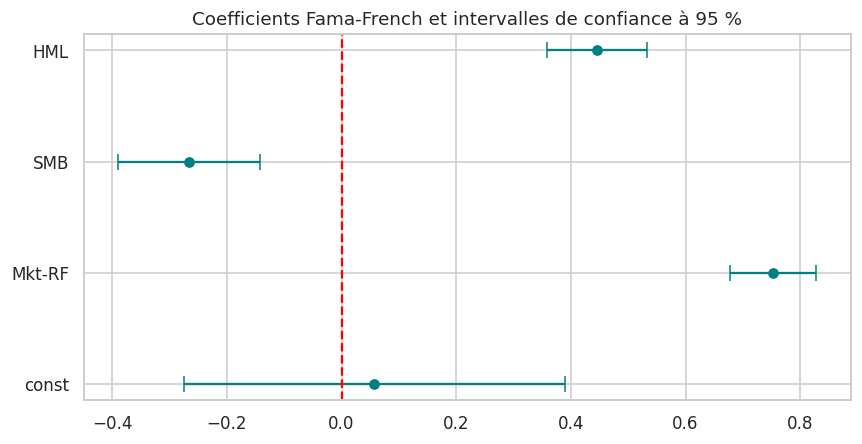

In [29]:
ci = m_ff3.conf_int()
coef = m_ff3.params
noms = list(coef.index)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.errorbar(coef.values, range(len(noms)),
            xerr=[coef.values - ci[0].values, ci[1].values - coef.values],
            fmt="o", capsize=5, color="teal")
ax.axvline(0, color="red", linestyle="--")
ax.set_yticks(range(len(noms)))
ax.set_yticklabels(noms)
ax.set_title("Coefficients Fama-French et intervalles de confiance à 95 %")
plt.tight_layout()
plt.show()

In [30]:
def signif(p): return "significatif" if p < 0.05 else "non significatif"

a, p_a = m_ff3.params["const"], m_ff3.pvalues["const"]
lo, hi = m_ff3.conf_int().loc["const"]
a_annuel = ((1 + a / 100) ** 12 - 1) * 100

print(f"1) Marché : bêta = {m_ff3.params['Mkt-RF']:.2f} ({signif(m_ff3.pvalues['Mkt-RF'])}). "
      f"Le portefeuille est {'plus' if m_ff3.params['Mkt-RF'] > 1 else 'moins'} sensible que le marché.")
print(f"2) Taille : bêta SMB = {m_ff3.params['SMB']:.2f} ({signif(m_ff3.pvalues['SMB'])}). "
      f"{'Biais vers les petites capitalisations.' if m_ff3.params['SMB'] > 0 else 'Biais vers les grandes capitalisations.'}")
print(f"3) Valeur : bêta HML = {m_ff3.params['HML']:.2f} ({signif(m_ff3.pvalues['HML'])}). "
      f"{'Biais Value.' if m_ff3.params['HML'] > 0 else 'Biais Croissance (Growth).'}")
print(f"4) Alpha = {a:.3f} %/mois (≈ {a_annuel:.1f} %/an), IC 95 % [{lo:.3f} ; {hi:.3f}], "
      f"p = {p_a:.3f} → {signif(p_a)}.")
print(f"5) R² ajusté : CAPM {m_capm.rsquared_adj:.2f} → Fama-French {m_ff3.rsquared_adj:.2f} ; "
      f"test F des facteurs ajoutés : p = {p_f:.3f} ({signif(p_f)}).")

1) Marché : bêta = 0.75 (significatif). Le portefeuille est moins sensible que le marché.
2) Taille : bêta SMB = -0.27 (significatif). Biais vers les grandes capitalisations.
3) Valeur : bêta HML = 0.45 (significatif). Biais Value.
4) Alpha = 0.057 %/mois (≈ 0.7 %/an), IC 95 % [-0.274 ; 0.389], p = 0.733 → non significatif.
5) R² ajusté : CAPM 0.61 → Fama-French 0.79 ; test F des facteurs ajoutés : p = 0.000 (significatif).


Le bêta de marché est de 0,753 (intervalle à 95 % de 0,678 à 0,828), nettement inférieur à 1 : le portefeuille est moins sensible que le marché, ce qui est cohérent avec sa composition défensive. Le bêta SMB de −0,265 (de −0,389 à −0,142) indique un comportement de grandes capitalisations, et le bêta HML de 0,446 (de 0,359 à 0,532) une orientation « valeur ». L'alpha (0,057 % par mois, soit environ 0,7 % par an) n'est pas significativement différent de zéro.

### 7.9 L'alpha peut-il venir du hasard ?

Pour mesurer l'incertitude de l'alpha sans hypothèse sur la forme des erreurs, on utilise le **bootstrap** : on retire au hasard (avec remise) des mois de l'échantillon, on réestime le modèle, et on répète l'opération 2000 fois. La dispersion des alphas obtenus montre à quel point l'estimation est instable.

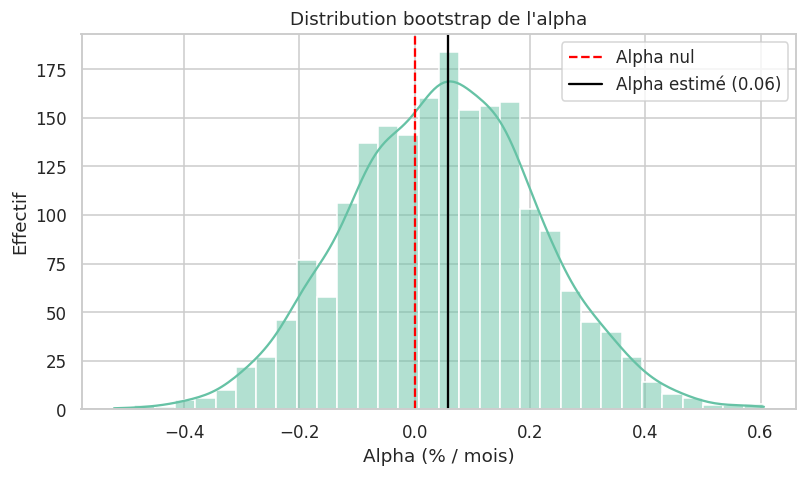

IC 95 % bootstrap de l'alpha : [-0.269 ; 0.371]  |  IC théorique : [-0.274 ; 0.389]


In [32]:
GRAINE = 42
rng = np.random.default_rng(GRAINE)
alphas_boot = []
for _ in range(2000):
    idx = rng.integers(0, len(data), len(data))
    m_b = sm.OLS(y.iloc[idx].values, X3.iloc[idx].values).fit()
    alphas_boot.append(m_b.params[0])
alphas_boot = np.array(alphas_boot)
b_lo, b_hi = np.percentile(alphas_boot, [2.5, 97.5])

fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.histplot(alphas_boot, kde=True, alpha=0.5, ax=ax)
ax.axvline(0, color="red", linestyle="--", label="Alpha nul")
ax.axvline(a, color="black", label=f"Alpha estimé ({a:.2f})")
ax.set_xlabel("Alpha (% / mois)")
ax.set_ylabel("Effectif")
ax.set_title("Distribution bootstrap de l'alpha")
ax.legend()
plt.tight_layout()
plt.show()
print(f"IC 95 % bootstrap de l'alpha : [{b_lo:.3f} ; {b_hi:.3f}]  |  IC théorique : [{lo:.3f} ; {hi:.3f}]")

L'intervalle bootstrap à 95 % de l'alpha ([−0,269 ; 0,371]) est très proche de l'intervalle théorique ([−0,274 ; 0,389]), ce qui conforte la robustesse de l'inférence. La distribution des alphas rééchantillonnés est centrée sur l'estimation ponctuelle et chevauche largement zéro : un alpha nul est parfaitement compatible avec les données.

### 7.10 Utiliser le modèle sur une nouvelle observation

Une fois estimé, le modèle donne le rendement en excès **attendu** pour des valeurs données des facteurs, avec un **intervalle de prédiction** qui reflète le risque propre du portefeuille.

In [33]:
nouveau_mois = pd.DataFrame([{"Mkt-RF": 2.0, "SMB": 0.5, "HML": -1.0}])   # mois fictif
X_new = sm.add_constant(nouveau_mois, has_constant="add")[X3.columns]

pred = m_ff3.get_prediction(X_new).summary_frame(alpha=0.05)
print("Facteurs : Mkt-RF=2.0 %, SMB=0.5 %, HML=-1.0 %")
print(f"Rendement en excès attendu : {pred['mean'].iloc[0]:.2f} %")
print(f"Intervalle de prédiction à 95 % : [{pred['obs_ci_lower'].iloc[0]:.2f} ; {pred['obs_ci_upper'].iloc[0]:.2f}] %")

Facteurs : Mkt-RF=2.0 %, SMB=0.5 %, HML=-1.0 %
Rendement en excès attendu : 0.98 %
Intervalle de prédiction à 95 % : [-2.72 ; 4.69] %


Pour un mois fictif où Mkt-RF vaut 2 %, SMB 0,5 % et HML −1 %, le modèle donne un rendement en excès attendu de 0,98 %, avec un intervalle de prédiction à 95 % de −2,72 % à 4,69 %. Même si les facteurs étaient connus, le rendement réalisé resterait très incertain : le modèle explique le risque, il ne prévoit pas le rendement.

## 8. Analyse critique

**Ce que les résultats montrent.** La rentabilité du portefeuille s'explique largement par le marché, la taille et la valeur (R² ajusté de 0,788 contre 0,606 pour le CAPM, gain confirmé par le test F, l'AIC et l'évaluation hors échantillon), et l'alpha n'est pas significatif. Les résultats sont robustes aux erreurs corrélées (Newey-West) et au bootstrap.

**Limites.**

- **Biais de survie** : le portefeuille est constitué d'entreprises encore cotées aujourd'hui ; les sociétés disparues, rachetées ou en difficulté sont absentes, ce qui tend à *surestimer* l'alpha. Le biais est probablement atténué (sélection fondée sur la taille et l'ancienneté, plusieurs titres décevants comme GE, AT&T et Pfizer) mais pas éliminé : l'alpha estimé ne peut pas être extrapolé à un investisseur qui aurait dû choisir ses titres en 2015.
- **Un alpha positif peut venir du hasard** : avec 132 observations, l'intervalle de confiance de l'alpha est large (environ ±0,33 % par mois). Tester plusieurs portefeuilles ou périodes augmenterait mécaniquement la probabilité d'obtenir un alpha « significatif » par chance ; ici il ne l'est pas.
- **Opérations sur titres** : les cours ajustés ne tiennent pas forcément compte de toutes les scissions (GE HealthCare, GE Vernova, WarnerMedia).
- **Portefeuille particulier** : dix grandes capitalisations à tendance défensive ; les conclusions sur SMB et HML valent pour ce portefeuille et non pour le marché américain. La pondération égale avec rééquilibrage mensuel ignore les coûts de transaction.
- **Modèle** : trois facteurs seulement (ni momentum, ni rentabilité, ni investissement) ; coefficients supposés constants alors que l'analyse glissante (7.7) montre qu'ils varient ; normalité des résidus rejetée.
- **Nature de l'évaluation hors échantillon** : les facteurs sont ceux du mois évalué ; elle mesure le pouvoir explicatif, pas la prévision.
- **Recouvrement** : le facteur de marché inclut les entreprises du portefeuille (voir 6.3, règle 7), ce qui renforce mécaniquement la corrélation avec le marché.
- **Révisions** : facteurs recalculés par CRSP et cours ajustés recalculés par Yahoo ; les chiffres dépendent de la date d'extraction (07/11/2026).

**Pistes d'amélioration.** Étendre le portefeuille (20 à 30 titres), comparer plusieurs périodes, ajouter les facteurs de momentum et de rentabilité (modèles à quatre ou cinq facteurs), comparer avec une méthode pénalisée (Ridge n° 2 ou Lasso n° 3 de l'annexe A, adaptées aux facteurs corrélés) et constituer le portefeuille selon une règle appliquée à la situation de fin 2014 pour limiter le biais de survie.

## 9. Conclusion

La rentabilité du portefeuille s'explique **largement** par le marché, la taille et la valeur : le modèle de Fama et French à trois facteurs explique environ 79 % de la variance des rendements mensuels en excès, contre 61 % pour le CAPM, et ce gain est statistiquement significatif.

L'objectif mesurable fixé en section 1 est atteint : R² ajusté de 0,788 contre 0,606 (CAPM), test F significatif (p < 0,0001), RMSE hors échantillon de 1,92 % contre 2,63 % (CAPM) et 2,99 % (référence), et intervalle de confiance de l'alpha ([−0,274 ; 0,389]) contenant 0.

Le portefeuille se caractérise par une sensibilité au marché inférieure à un (0,75), un biais vers les grandes capitalisations (−0,27) et un biais « valeur » (0,45). L'alpha estimé (environ 0,06 % par mois, soit 0,7 % par an) n'est pas significativement différent de zéro : la rentabilité moyenne rémunère l'exposition aux facteurs de risque et n'indique pas de performance anormale. Ces résultats sont à interpréter avec prudence : échantillon de 132 mois, portefeuille de dix titres, biais de survie résiduel et coefficients qui varient dans le temps.

## 10. Références

- Fama, E. F. et French, K. R. (1993). Common risk factors in the returns on stocks and bonds. *Journal of Financial Economics*, 33(1), 3-56.
- Newey, W. K. et West, K. D. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica*, 55(3), 703-708.
- Seabold, S. et Perktold, J. (2010). Statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th Python in Science Conference*.
- Données des facteurs : Kenneth R. French, *Data Library*, Tuck School of Business, Dartmouth College (fichier `F-F_Research_Data_Factors_CSV.zip`, consulté le 07/11/2026).
- Cours des titres : Yahoo Finance, via la bibliothèque Python `yfinance` (consulté le 07/11/2026).
- Annexe A du support de cours : « 29 exemples Python — principaux algorithmes de Machine Learning », algorithme n° 1 (régression linéaire).

## Déclaration des ressources et outils d'IA

- **Ressources** : données publiques Fama-French (Dartmouth) et Yahoo Finance ; bibliothèques Python `pandas`, `numpy`, `statsmodels`, `matplotlib`, `seaborn`, `yfinance` ; annexe A du support de cours.
- **Outil d'IA** : Claude (Anthropic) a été utilisé comme aide à la rédaction (fiche de cadrage, description du jeu de données, restructuration du notebook selon le plan imposé, commentaires des résultats). Les chiffres commentés proviennent de l'exécution du notebook. [À adapter ou compléter selon votre usage réel et les exigences de la section 11 de l'énoncé.]